<div align="center">

# Transformer vs S4 vs Mamba vs RD-S4 (v1 and v2)
### Four architectures and two RD-S4 generations, 1.7 M parameters, equal training FLOPs, one RTX 5050

</div>

**Result (second edition, with RD-S4 v2).** At equal parameters (1.7 M) and equal training FLOPs (4.34e14),
with every arm's own learning-rate sweep and three seeds, **RD-S4 v2 moves RD-S4 from last to second of five.** Its
test perplexity is 2.012 per character (CE 0.699 ± 0.003), against 1.941 for Mamba, 2.092 for S4, 2.154 for the
Transformer and 2.177 for RD-S4 v1. It beats S4, the Transformer and v1 in every seed and at 8K, 32K and 128K. Its
in-window retrieval is below Mamba's in every seed at a gap of 32 characters (+0.040 against +0.074) and not distinguishable from Mamba's at a gap of 192 characters (+0.039 against +0.056; two-sided p = 0.3). It is the only arm whose mean quality improves at every
length when it may use context beyond its 512-character training window, though only by 0.001 to 0.002 nats
(Mamba stays within 0.001 of zero; the other arms lose). Against v1 it prefills 2.6x faster with 4.2x less memory, decodes
1.26x faster and reaches v1's final quality with 48 percent of the budget. **It does not clear the bar against
Mamba:** it is 0.036 nats per character behind in every seed, prefills 2.7x slower, decodes 13 percent slower and
carries a 30 percent larger state. Of the brain-inspired learning rules, learning from prediction errors pays where
it runs inside the forward pass (v2's memory) and where it protects old knowledge while the model is taught new text
(orthogonal consolidation). Predictive-coding relaxation in place of backprop, and the surprise gate in one-pass
pre-training, cost more than they return on a GPU.


## 1. The question, and the bar it has to clear

> *If RD-S4 maintains comparable or better perplexity and materially lower memory and latency at 32K to 128K
> context, then the research starts becoming genuinely compelling rather than merely an interesting SSM variant.*

That sentence is the acceptance test. Every number below is measured on the same laptop RTX 5050 (8 GB), with the
GPU otherwise idle, by one harness that treats every arm identically. Nothing is reported from a single seed.

### What changed: RD-S4 v2

The first edition of this benchmark found three reasons for RD-S4's last place: its recurrence was time-invariant,
so the input could not steer the state token by token; a quarter of its forward arithmetic went to auxiliary heads
that did not lower cross-entropy; and its FFT prefill was slow and memory-hungry. **RD-S4 v2** is the revision that
answers those findings, and it carries the lesson of the predictive-coding study (SPOC,
`digit_predictor_predictive_coding.ipynb`) into the architecture itself:

* **Learning by prediction error, inside the forward pass.** Every head keeps an associative memory that first
  predicts the incoming token's value from its key and then stores only the error: the local predictive-coding
  rule, run at every token, in parallel across the sequence, with no backward pass. A token that is already
  predicted changes nothing (a built-in surprise gate), and a write only touches the directions it uses (built-in
  protection of what is stored).
* **Resonance.** The memory's key space evolves under a bank of damped resonant modes whose step size is chosen by
  the input at every token.
* **GPU form.** Training runs an exact chunked parallel algorithm on tensor cores (agreement with the token-by-token
  definition: 1e-15 in float64, gradients included); decoding updates a fixed-size state. No FFT, no custom kernel.
* **What was removed.** v1's draft heads, router, operator dictionary and in-network evolution showed no measurable
  benefit and are gone. The JEPA objective (predicting future latent summaries) stays as a training-only head.

v2's shape was chosen with pilot runs scored on the selection split at 40 percent of the budget, and its learning
rate by the same sweep as every other arm. It is then measured with exactly the protocol of the other arms.


## 2. Protocol

| | |
|---|---|
| **Data** | TinyStories, character level, one shared 75-symbol vocabulary. 80 M training characters; a 1 M-character *probe* split carved from training data (used only by RD-S4's in-network evolution); a 2 M-character *selection* split (learning-rate choice only); a disjoint *test* split from the official validation file (all reported numbers). |
| **Size** | Every arm matched to RD-S4's 1,721,760 parameters within 1 percent (RD-S4 v2: 1,719,980 trained, of which 1,710,536 are used at inference). |
| **Compute** | Equal **training FLOPs** for every arm: 4.34e14, set by 34 M tokens (about 20 per parameter) for the Transformer. Dense contractions are counted at the dispatcher, forward and backward, complex matmuls weighted 4x; attention, FFT convolutions and scans are added analytically (x3 for training). RD-S4's evolution forward passes are charged to its budget. Arms that are cheaper per token therefore see more tokens. |
| **Optimisation** | Shared AdamW recipe (betas 0.9/0.95, weight decay 0.05 on matrices only, clip 1.0, 4 percent warm-up, cosine to 10 percent), batch 32 x 512 characters, fp32 weights with TF32 matmuls. S4 keeps its published rule (A and dt at min(lr, 1e-3), no decay). RD-S4 keeps its own optimiser, full objective (CE + JEPA + VICReg + PTV drafts + router balance), EMA teacher, and evolution. |
| **Fairness** | A learning-rate sweep for **every** arm (1.5e-3, 3e-3, 6e-3, extended if the optimum sits on an edge), selected on the selection split, then 3 seeds at the selected rate. Final weights for everyone: no checkpoint picking. RD-S4 v2's design was fixed by pilots on the selection split at 40 percent of the budget, before any of its test-split numbers existed. |
| **Arms** | **Transformer**: pre-norm GPT, RoPE, d=192, 4 layers, 6 heads. **S4**: S4D-Lin with ZOH, 64 complex modes per channel, GLU, d=192, 4 layers. **Mamba**: Mamba-1, d=188, 7 layers, expand 2, d_state 16, reference initialisation. **RD-S4**: the notebook's `RDS4LM`, loaded from the notebook source and not modified. **RD-S4 v2**: the revised architecture (resonant predictive-coding memory, 6 layers, d=188); its source is proprietary and not part of this notebook. |
| **Kernels** | The Transformer uses PyTorch's flash attention for prefill and a bandwidth-bound matmul decode (measured 11x faster at 128K than the fused kernel, so the baseline gets its best case). Mamba's official CUDA kernels cannot be built here (nvcc 12.4 has no sm_120 target), so its selective scan runs in a fused Triton kernel written for this benchmark and verified against a float64 reference (relative error about 1e-7 on outputs, states and all six gradients). S4 and RD-S4 share the notebook's exact chunked long-context routine. RD-S4 v2 runs in plain PyTorch operations with no custom kernel (its training step is fused by `torch.compile`, which changes wall-clock only; its FLOPs are counted on the eager graph). Every arm uses the same fused RMSNorm kernel. |
| **Long context** | Trained at 512 characters, evaluated at 8K, 32K and 128K: 16x to 256x beyond the training length, for every arm, with full context and with a 512-character window on the same characters. |


In [1]:
import sys, os, json, math
sys.path.insert(0, os.path.join(os.getcwd(), "benchmarks", "four_way"))
import matplotlib
%matplotlib inline
import report as RP
R = RP.load_extra(RP.load_all())
plan = R["plan"]
print(f"device      : {plan['gpu']['gpu']}")
print(f"RD-S4 source: {plan['rds4_provenance']['notebook']}  sha256 {plan['rds4_provenance']['sha256'][:16]}...")
pv2 = plan.get('rds4_v2_provenance', {})
if pv2:
    print(f"RD-S4 v2    : {pv2['notebook']}  code sha256 {pv2['code_sha256'][:16]}... (source not included here)")
print(f"budget      : {plan['budget_flops']:.3e} training FLOPs per arm\n")
print(f"{'arm':<12}{'params':>11}{'FLOPs/token':>14}{'steps':>8}{'tokens':>10}{'evolution share':>17}")
for a, r in plan["arms"].items():
    print(f"{a:<12}{r['params']:>11,}{r['per_step']/16384/1e6:>12.2f} M{r['steps']:>8,}{r['tokens']/1e6:>9.1f}M"
          f"{100*r['evolution_flops_total']/plan['budget_flops']:>16.1f}%")
print("\nparity of every fast path against the parallel forward (random weights):")
for a, r in R["check"]["random_init"].items():
    print(f"  {a:<12} streamed NLL max |diff| {r['stream_vs_parallel_max_abs_nll']:.1e}   decode max rel {r['decode_vs_parallel_max_rel_logit']:.1e}")

device      : NVIDIA GeForce RTX 5050 Laptop GPU, 580.178.04, 204 MiB, 8151 MiB, 43, 14.34 W, 2205 MHz, 9001 MHz, 0x0000000000000004
RD-S4 source: RD-S4_EFR_TinyStories.ipynb  sha256 db9cda75bc1afcce...
RD-S4 v2    : RD-S4_EFR_TinyStories.ipynb  code sha256 497c5e870e3e1754... (source not included here)
budget      : 4.342e+14 training FLOPs per arm

arm              params   FLOPs/token   steps    tokens  evolution share
Transformer   1,736,448       12.77 M   2,075     34.0M             0.0%
S4            1,714,944        9.37 M   2,829     46.4M             0.0%
Mamba         1,707,980       10.82 M   2,448     40.1M             0.0%
RD-S4         1,721,760        8.76 M   2,858     46.8M             5.5%
RD-S4 v2      1,719,980       12.83 M   2,065     33.8M             0.0%

parity of every fast path against the parallel forward (random weights):
  Transformer  streamed NLL max |diff| 0.0e+00   decode max rel 8.4e-03
  S4           streamed NLL max |diff| 3.1e-04   decode max rel

### 3. 🧪 `[T | S4 | Mamba | RD-S4 | v2]` Results ①: training at equal FLOPs

Left: held-out CE against compute for each arm at its selected learning rate (line = mean, band = min to max over 3 seeds). Right: the sweep that chose it. A head-to-head won by giving another architecture a bad learning rate is not a result.

{
 "Transformer": {
  "0.0015": 0.7580692730844021,
  "0.003": 0.732774393633008,
  "0.006": 0.733587559312582
 },
 "S4": {
  "0.0015": 0.7531482856720686,
  "0.003": 0.7211004607379436,
  "0.006": 0.705428458750248,
  "0.012": 0.7077387180179358
 },
 "Mamba": {
  "0.0015": 0.6800996102392673,
  "0.003": 0.6579927690327168,
  "0.006": 0.6403956115245819,
  "0.012": 0.6313788946717978,
  "0.024": 0.6419893261045218
 },
 "RD-S4": {
  "0.0015": 0.7781689446419477,
  "0.003": 0.7599627338349819,
  "0.006": 0.7508140541613102,
  "0.012": 0.7491812705993652,
  "0.024": 0.7535642106086016
 },
 "RD-S4 v2": {
  "0.0015": 0.6772171389311552,
  "0.003": 0.6683442089706659,
  "0.006": 0.6664371155202389,
  "0.012": 0.6716180201619864
 }
}


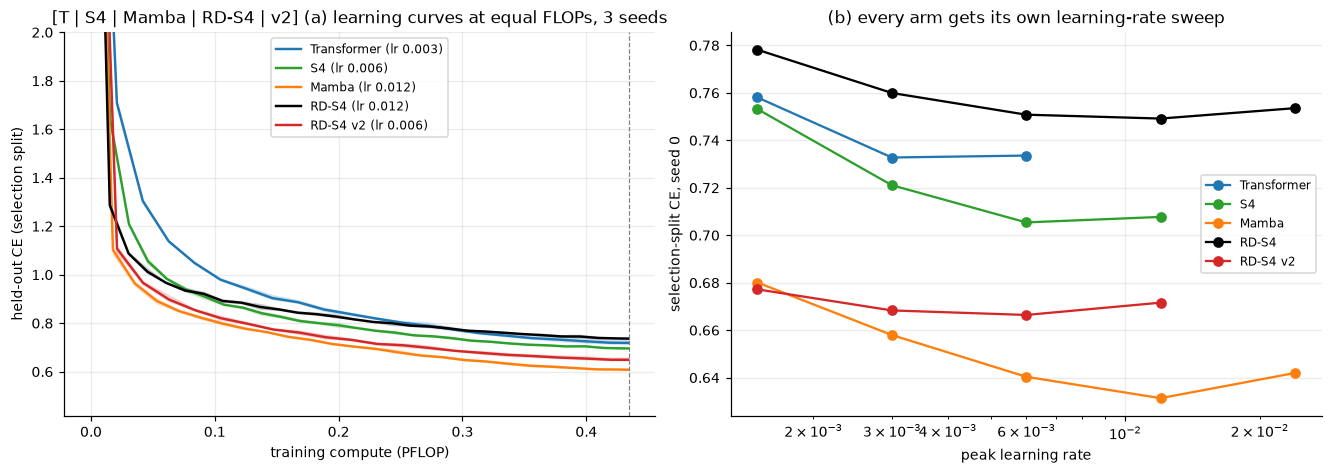

In [2]:
RP.fig_training(R);
print(json.dumps({a: R['sweep'][a]['select_ce'] for a in RP.C.ARMS}, indent=1))

### 4. 🧪 `[T | S4 | Mamba | RD-S4 | v2]` Results ②: quality (cross-entropy, perplexity, accuracy)

Test split, 4,096 windows of 512 characters (2.1 M characters). Perplexity is per character. p-values are exact permutation tests over all relabellings of the per-seed values; with 3 seeds a side the smallest attainable value is 0.05 one-sided (0.10 two-sided), which therefore means complete separation.

model     vs           metric                  model    other     diff  p(1-sided)  p(2-sided)
RD-S4     Transformer  test CE                0.7780   0.7675  +0.0105       1.000       0.100
RD-S4     Transformer  CE@8K full             0.7966   4.2515  -3.4549       0.050       0.100
RD-S4     Transformer  CE@32K full            0.7519   4.5495  -3.7976       0.050       0.100
RD-S4     Transformer  CE@128K full           0.7564   4.5988  -3.8425       0.050       0.100
RD-S4     Transformer  retrieval@32           0.0100   0.0243  -0.0144       0.900       0.300
RD-S4     Transformer  retrieval@192          0.0019   0.0125  -0.0105       1.000       0.100
RD-S4     S4           test CE                0.7780   0.7383  +0.0398       1.000       0.100
RD-S4     S4           CE@8K full             0.7966   0.7846  +0.0120       1.000       0.100
RD-S4     S4           CE@32K full            0.7519   0.7457  +0.0063       0.950       0.200
RD-S4     S4           CE@128K full           0.75

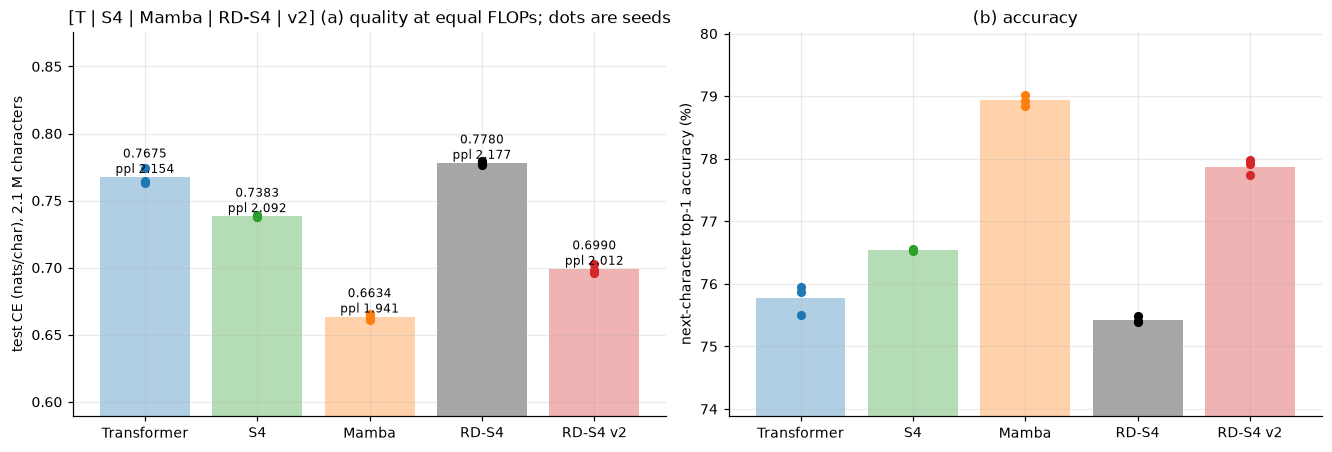

In [3]:
RP.fig_quality(R)
sig = RP.significance(R)
print(f"{'model':<10}{'vs':<13}{'metric':<20}{'model':>9}{'other':>9}{'diff':>9}{'p(1-sided)':>12}{'p(2-sided)':>12}")
for s in sig:
    if s["metric"] in ("test CE", "CE@8K full", "CE@32K full", "CE@128K full", "retrieval@32", "retrieval@192"):
        print(f"{s['model']:<10}{s['baseline']:<13}{s['metric']:<20}{s['rd_s4']:>9.4f}{s['baseline_mean']:>9.4f}"
              f"{s['diff']:>+9.4f}{s['p_one_sided']:>12.3f}{s['p_two_sided']:>12.3f}")
print("(every metric, including retrieval at every gap, is in results/significance.json)")

### 5. 🧪 `[T | S4 | Mamba | RD-S4 | v2]` Results ③: does quality survive 8K, 32K and 128K of context?

Four 131,072-character test streams, scored at every position. **Full context**: the Transformer attends over everything before; the recurrent arms carry their state across 2,048-character chunks (verified exact). **512 window**: the same characters re-scored when every prediction may use at most the 512 characters a model was trained on. Panel (b) shows each arm in the configuration that can actually be deployed at that length (a Transformer trained at 512 would be served with a window). Panel (c) is the cleanest long-context number in this notebook: on identical characters, how much better (or worse) the model does when it also has everything beyond the last 512 characters.

arm                  @8K full   window     gain    @32K full   window     gain   @128K full   window     gain
Transformer            4.2515   0.7796  -3.4719       4.5495   0.7397  -3.8099       4.5988   0.7422  -3.8566
S4                     0.7846   0.7561  -0.0285       0.7457   0.7136  -0.0321       0.7449   0.7108  -0.0341
Mamba                  0.6722   0.6709  -0.0012       0.6319   0.6321  +0.0002       0.6319   0.6315  -0.0004
RD-S4                  0.7966   0.7942  -0.0024       0.7519   0.7488  -0.0031       0.7564   0.7544  -0.0020
RD-S4 v2               0.7053   0.7060  +0.0007       0.6704   0.6722  +0.0019       0.6689   0.6697  +0.0007


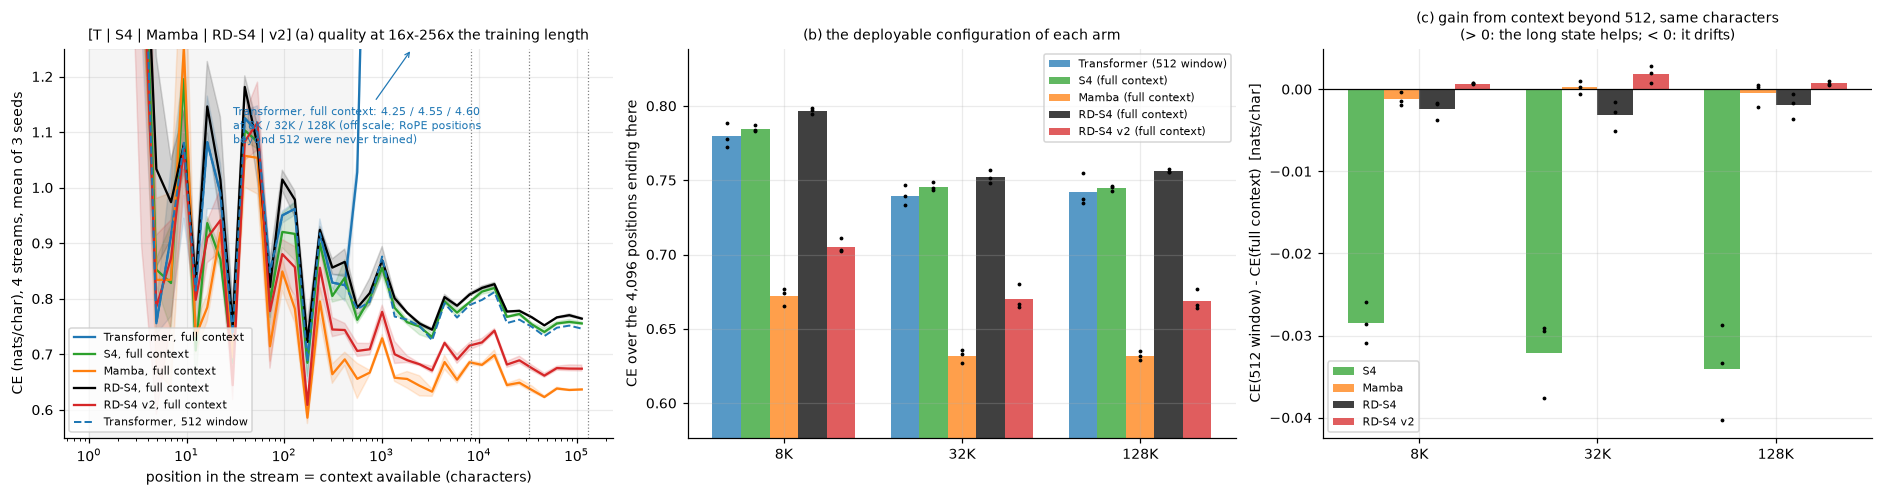

In [4]:
RP.fig_long(R)
print(f"{'arm':<12}{'':>4}" + "".join(f"{f'@{c//1024}K full':>13}{'window':>9}{'gain':>9}" for c in RP.P.long_ctx))
for a in RP.C.ARMS:
    es = RP.evals2(R, a)
    row = ""
    for c in RP.P.long_ctx:
        k = str(c)
        f = sum(e['context'][k]['ce_full'] for e in es) / len(es)
        w = sum(e['context'][k]['ce_window'] for e in es) / len(es)
        row += f"{f:>13.4f}{w:>9.4f}{w - f:>+9.4f}"
    print(f"{a:<12}{'':>4}" + row)

### 6. 🧪 `[T | S4 | Mamba | RD-S4 | v2]` Results ④: long-range retrieval, as a controlled experiment

Two sequences are built for every trial and differ in exactly one 128-character slot near the start. In the *treated* sequence the slot holds a test passage; in the *control* it holds a different passage. Both continue with the same gap of unrelated text and then the same passage. The score is CE(control) minus CE(treated) on characters 17 to 128 of that final passage, so everything except the earlier copy is held fixed. 8 passages per gap, 3 seeds. Gaps of 32 and 192 fit inside the 512-character training window for every arm; the rest are 4x to 256x beyond it. No arm was trained on this task.

*Design note:* an earlier version of this test compared a passage's first appearance with its repeat. That confounds retrieval with position (the two copies sit at different depths with different text before them), and for the Transformer it mostly measured positions beyond 512. It was replaced by this controlled version before any conclusion was drawn; its raw output remains in `results/eval/` for transparency.

arm                gap 32      gap 192    gap 2,048    gap 8,192   gap 32,768  gap 131,072
Transformer       +0.0243      +0.0125      +0.0004      -0.0035      +0.0048      +0.0029
S4                +0.0115      +0.0029      -0.0006      +0.0000      +0.0000      +0.0000
Mamba             +0.0741      +0.0565      +0.0007      +0.0000      -0.0000      +0.0000
RD-S4             +0.0100      +0.0019      +0.0002      -0.0000      +0.0000      +0.0000
RD-S4 v2          +0.0397      +0.0395      +0.0000      +0.0000      +0.0000      +0.0000
(Transformer values beyond gap 192 use positions it was never trained on; with a 512 window its gain there is 0 by construction.)


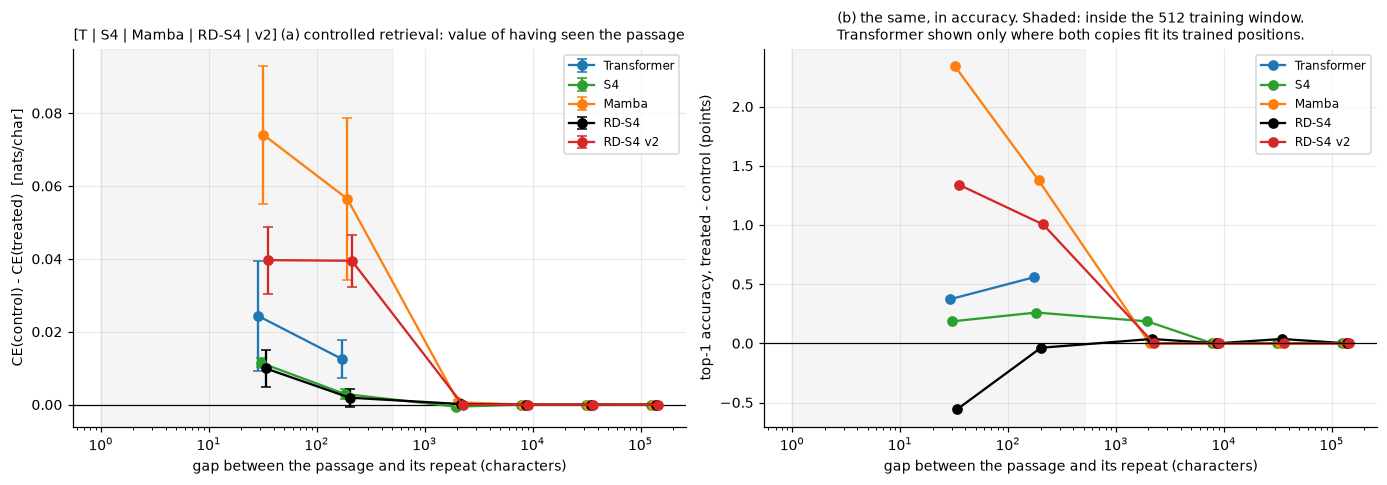

In [5]:
RP.fig_retrieval(R)
print(f"{'arm':<12}" + "".join(f"{f'gap {D:,}':>13}" for D in RP.P.retrieval_gaps))
for a in RP.C.ARMS:
    es = RP.evals2(R, a)
    print(f"{a:<12}" + "".join(f"{sum(e['retrieval'][str(D)]['gain'] for e in es)/len(es):>+13.4f}" for D in RP.P.retrieval_gaps))
print("(Transformer values beyond gap 192 use positions it was never trained on; with a 512 window its gain there is 0 by construction.)")

### 7. 🧪 `[T | S4 | Mamba | RD-S4 | v2]` Results ⑤: prefill, decode and memory at 2K to 128K

Batch 1, seed-0 weights, real test text, median of 3 interleaved rounds after a warm-up. Prefill produces the decode-ready state (the Transformer writes its bf16 KV cache in one flash-attention pass; the recurrent arms process 2,048-character chunks, the setting the chunk sweep below shows to be fastest or within 3 percent of fastest for each of them, at a quarter of the memory of 8,192). Decode generates 128 tokens greedily, eagerly and with CUDA graphs (32 steps per graph, one RD-S4 routing window), which removes Python launch overhead equally for every arm. Peak memory is the working set above the weights.

precision: {
 "Transformer": "bf16 autocast, bf16 KV cache; flash-attention prefill; bandwidth-bound matmul decode attention (inference); fp32/TF32 (training)",
 "S4": "fp32 (TF32 matmul)",
 "Mamba": "fp32 (TF32 matmul); selective scan in a fused Triton kernel",
 "RD-S4": "fp32 (TF32 matmul)",
 "RD-S4 v2": "fp32 (TF32 matmul); chunked parallel form on tensor cores, no custom kernels"
}

prefill chunk trade-off at 128K (recurrent arms):
  S4      chunk   2048:    60,478 tok/s   391.2 MB  chunk   8192:    62,620 tok/s  1561.1 MB  chunk  32768:       nan tok/s     nan MB
  Mamba   chunk   2048:   390,185 tok/s    29.1 MB  chunk   8192:   249,931 tok/s   115.8 MB  chunk  32768:   233,921 tok/s   459.2 MB
  RD-S4   chunk   2048:    58,021 tok/s   410.2 MB  chunk   8192:    57,755 tok/s  1633.0 MB  chunk  32768:    55,343 tok/s  6309.3 MB
  RD-S4 v2chunk   2048:   140,446 tok/s    98.8 MB  chunk   8192:   128,637 tok/s   372.1 MB  chunk  32768:    98,501 tok/s  1471.1 MB

prefill replayed fr

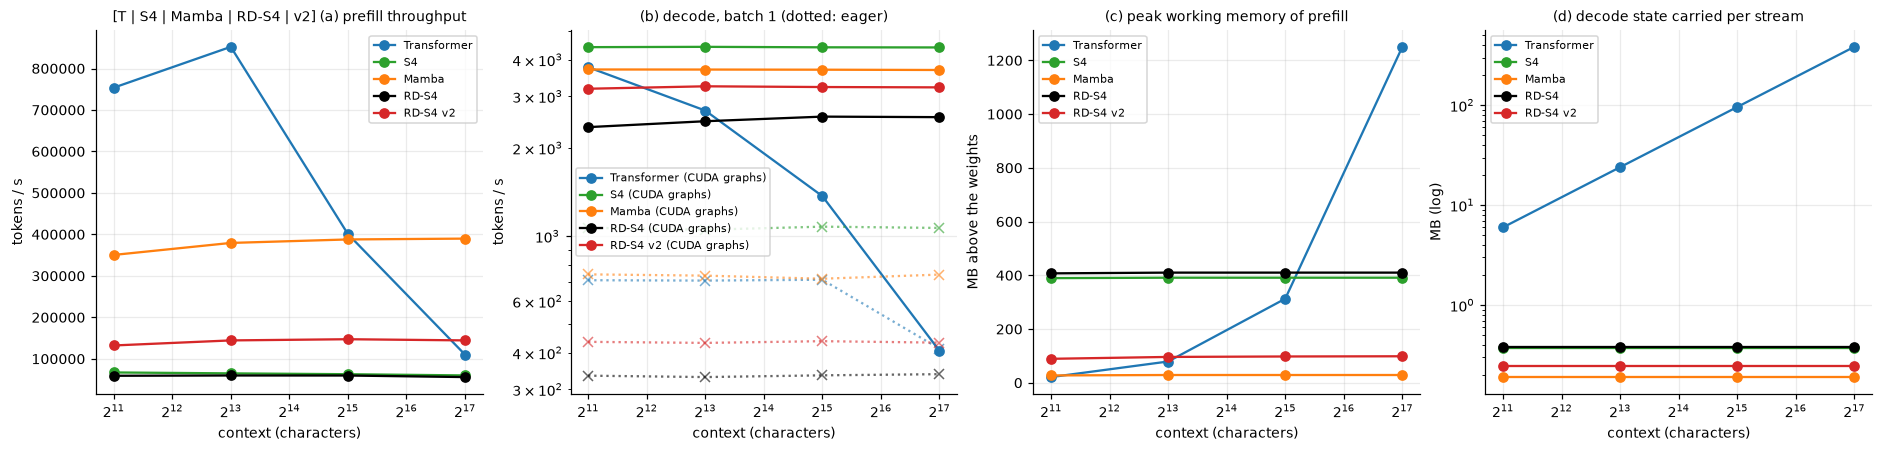

In [6]:
RP.fig_efficiency(R)
sp = R["speed"]
print("precision:", json.dumps(sp["precision"], indent=1))
print("\nprefill chunk trade-off at 128K (recurrent arms):")
for a, d in sp["chunk_sweep_128k"].items():
    print(f"  {a:<8}" + "  ".join(f"chunk {k:>6}: {v['prefill_tok_s']:>9,.0f} tok/s {v['peak_mb']:>7.1f} MB" for k, v in d.items()))
print("\nprefill replayed from one CUDA graph per 2,048-character chunk (same kernels, no launch overhead):")
for a, d in sp.get("graph_prefill", {}).items():
    if "error" in d:
        print(f"  {a:<9} not capturable: {d['error']}"); continue
    print(f"  {a:<9}" + "  ".join(f"{int(c)//1024:>3}K {v['prefill_tok_s']:>9,.0f} tok/s" for c, v in d.items() if c.isdigit())
          + f"   (|logit diff| vs eager {d['max_abs_logit_diff_vs_eager']:.1e})")
spc = R.get("speed_compiled")
if spc:
    print("\nsupplementary: every chunked recurrent arm compiled by TorchInductor (fixed shapes), same weights:")
    for a, d in spc["arms"].items():
        if "error" in d:
            print(f"  {a:<9} failed: {d['error']}"); continue
        print(f"  {a:<9} prefill " + "  ".join(f"{int(c)//1024:>3}K {v['compiled_prefill_tok_s']:>9,.0f} (+graph {v['compiled_graph_prefill_tok_s']:>9,.0f}) tok/s"
              for c, v in d.items() if c.isdigit()) + f"   decode @32K {d['decode_compiled_graph_tok_s_32k']:,.0f} tok/s"
              + f"   |logit diff| {d['max_abs_logit_diff_vs_eager']:.1e}")
print("\nGPU before:", sp["gpu_before"]["gpu"]); print("GPU after :", sp["gpu_after"]["gpu"])

### 8. 🧪 `[T | S4 | Mamba | RD-S4 | v2]` Results ⑥: training time to a given quality

The same training runs as section 3, plotted against wall-clock on this GPU instead of FLOPs (one-off compilation excluded and reported separately). The marker on each curve is where that arm first reaches the final quality of RD-S4 v1.

target: final held-out curve CE of RD-S4 v1 = 0.7365
arm           ms/step   full run  reaches it at step   budget  minutes
Transformer        65      2.3 m               1,800      87%      2.0
S4                 72      3.4 m               2,000      71%      2.4
Mamba             140      5.7 m               1,000      41%      2.3
RD-S4             147      7.0 m               2,857     100%      7.0
RD-S4 v2          152      5.2 m               1,000      48%      2.5
RD-S4 v2 one-off compilation per run: 3 to 6 s


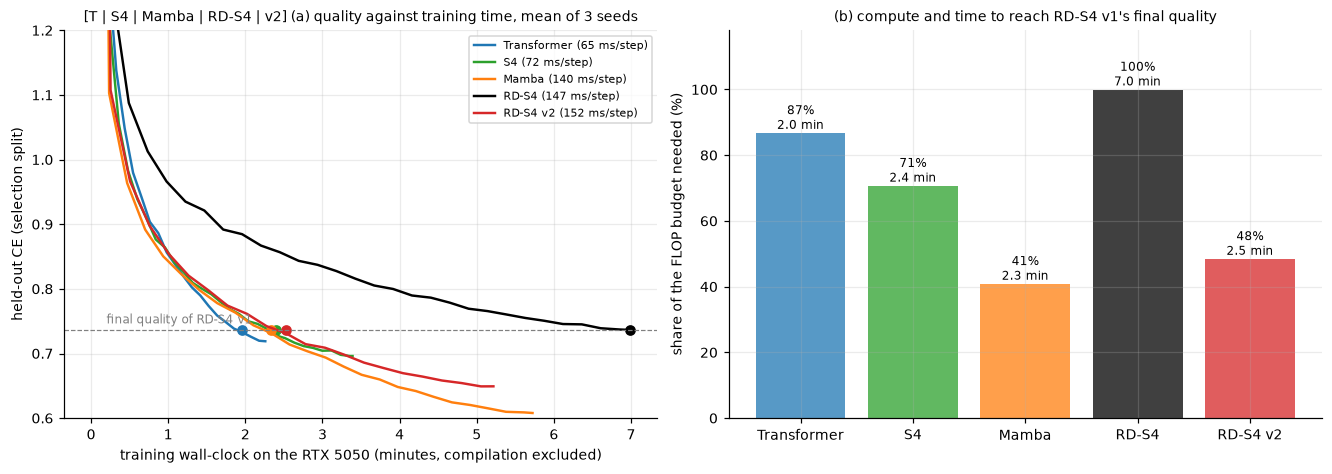

In [7]:
fig, ttq = RP.fig_time_to_quality(R)
print(f"target: final held-out curve CE of RD-S4 v1 = {ttq['target_curve_ce']:.4f}")
print(f"{'arm':<12}{'ms/step':>9}{'full run':>11}{'reaches it at step':>20}{'budget':>9}{'minutes':>9}")
for a, r in ttq["arms"].items():
    hit = f"{r['step']:>20,}{100*r['budget_fraction']:>8.0f}%{r['minutes']:>9.1f}" if "step" in r else f"{'never':>20}"
    print(f"{a:<12}{1e3*r['sec_per_step']:>9.0f}{r['full_run_minutes']:>9.1f} m{hit}")
v2 = [R["runs"][k] for k in R["runs"] if k[0] == "RD-S4 v2" and "first_step_s" in R["runs"][k]]
if v2:
    print(f"RD-S4 v2 one-off compilation per run: {min(r['first_step_s'] for r in v2):.0f} to {max(r['first_step_s'] for r in v2):.0f} s")

### 9. 🧪 SPOC on RD-S4 v2: what the brain-inspired learning rules do on a GPU

The digit study separated SPOC into three mechanisms. Each is tested here on RD-S4 v2:

* **(a) Surprise gate in pre-training.** Twice the batch is screened by a forward pass without gradients, and
  windows are learned in proportion to how badly they are predicted, importance-weighted so that the update stays
  unbiased. The screening is charged to the same FLOP budget.
* **(b) Predictive-coding relaxation instead of backprop.** Value nodes at every block output relax towards
  equilibrium (T sweeps, all blocks in parallel), then every block updates from its own local error. PC recomputes
  predictions at every sweep, as in the digit study; PC-FPA freezes them at the feed-forward pass, which is known
  to reproduce backprop's gradient exactly after enough sweeps. Measured: GPU time and FLOPs per weight update
  relative to backprop, alignment (cosine) of the update with the exact gradient, a race at equal wall-clock, and
  the same code on a classic predictive-coding MLP as a control.
* **(c) Day-dreaming: teaching new text without forgetting.** The trained RD-S4 v2 (all three seeds) is taught
  *As You Like It*, the book this project started from. 85 percent of the play is taught for 8 passes, 5 percent
  only calibrates the surprise gate, and the last 10 percent is never taught and measures whether the new style
  was learned. TinyStories windows measure forgetting. SPOC (surprise gate + orthogonal consolidation) is compared
  with standard fine-tuning and with each mechanism alone; every method gets the same passes and step size.


(a) pre-training, seed 0, equal FLOPs: plain 0.6664 (33.8 M chars learned)  vs gated 0.7365 (20.4 M learned, 40.8 M screened)
(b) backprop: 320 ms per update
    pc      T= 1:  2.2x the time,  2.0x the FLOPs, cos to exact gradient +0.594
    pc      T= 2:  3.2x the time,  2.8x the FLOPs, cos to exact gradient +0.345
    pc      T= 6:  7.1x the time,  5.7x the FLOPs, cos to exact gradient -0.006
    pc      T= 7:  8.0x the time,  6.5x the FLOPs, cos to exact gradient -0.006
    pc      T=12: 12.9x the time, 10.1x the FLOPs, cos to exact gradient +0.006
    pc      T=24: 24.6x the time, 18.9x the FLOPs, cos to exact gradient +0.014
    pc_small T= 1:  2.2x the time,  2.0x the FLOPs, cos to exact gradient +0.595
    pc_small T= 2:  3.2x the time,  2.8x the FLOPs, cos to exact gradient +0.004
    pc_small T= 6:  7.1x the time,  5.7x the FLOPs, cos to exact gradient -0.015
    pc_small T= 7:  8.0x the time,  6.5x the FLOPs, cos to exact gradient -0.008
    pc_small T=12: 12.9x the time, 10.

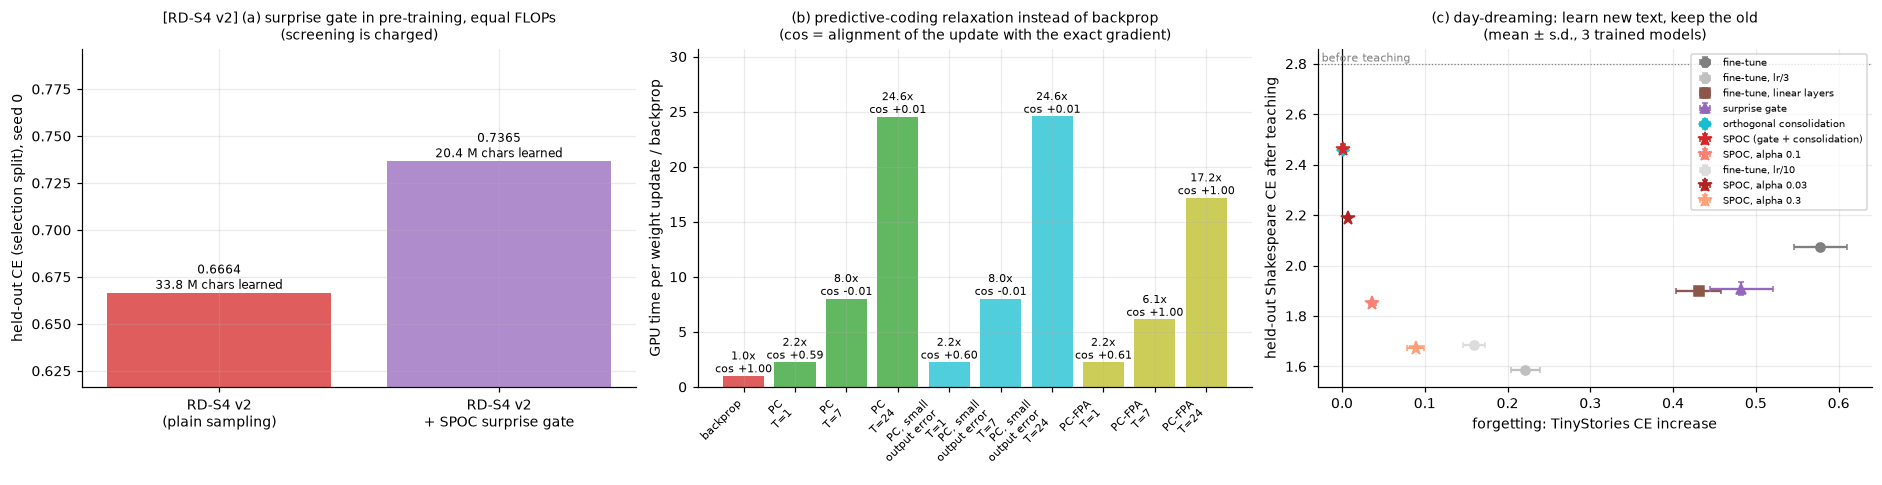

In [8]:
RP.fig_spoc(R)
ab = R.get("ablate") or {}
if ab.get("gate"):
    g = ab["gate"]; b = R["runs"][("RD-S4 v2", g["lr"], g["seed"])]
    print(f"(a) pre-training, seed 0, equal FLOPs: plain {b['select_ce']:.4f} ({b['tokens']/1e6:.1f} M chars learned)  "
          f"vs gated {g['select_ce']:.4f} ({g['tokens_trained']/1e6:.1f} M learned, {g['tokens_screened']/1e6:.1f} M screened)")
pc = R.get("pc")
if pc:
    print(f"(b) backprop: {1e3*pc['backprop']['seconds']:.0f} ms per update")
    for key in ("pc", "pc_small", "pc_fpa"):
        for T, r in pc.get(key, {}).items():
            print(f"    {key:7s} T={T:>2}: {r['time_ratio']:4.1f}x the time, {r['flop_ratio']:4.1f}x the FLOPs, "
                  f"cos to exact gradient {r['cosine_to_backprop']:+.3f}")
    for n, r in pc["race_equal_wallclock"].items():
        print(f"    equal wall-clock race, {n:<16}: {r['updates']:>4} updates -> selection CE {r['select_ce']:.4f}")
ps_ = R.get("pc_steps")
if ps_:
    print("(b') plain PC with smaller relaxation steps (stability), cosine to the exact gradient:")
    for k, r in ps_["grid"].items():
        print(f"    output-error scale {r['beta_out']:<5g} gamma {r['gamma']:<5g} T={r['T']:>2}: {r['time_ratio']:5.1f}x backprop  cos {r['cosine_to_backprop']:+.3f}")
    for n, r in ps_["race_equal_wallclock"].items():
        print(f"    equal wall-clock race, {n}: {r['updates']} updates -> selection CE {r['select_ce']:.4f}")
pp_ = R.get("pc_precision")
if pp_:
    print("(b'') plain PC on 8 windows, gamma 0.1: TF32 vs full fp32 arithmetic, and a separate stable step for x_0:")
    for k, c in pp_["cosine_to_backprop"].items():
        print(f"    {k:<28} cos {c:+.3f}")
    for k, c in pp_.get("per_layer_step", {}).items():
        print(f"    {k:<36} cos {c:+.3f}")
jt = RP.jepa_ablation(R)
if jt:
    print(f"JEPA ablation (3 seeds each, test CE): with {jt['with_jepa'][0]:.4f} ± {jt['with_jepa'][1]:.4f}, "
          f"without {jt['without_jepa'][0]:.4f} ± {jt['without_jepa'][1]:.4f}, diff {jt['diff']:+.4f}, "
          f"p two-sided {jt['p_two_sided']:.2f} (one-sided, JEPA better: {jt['p_one_sided']:.2f})")

method                           held-out CE   learned  forgetting  backward  screened  seconds
fine-tune                        2.074±0.011    +0.725     +0.5778      1632         0     16.4
fine-tune, lr/3                  1.584±0.005    +1.214     +0.2215      1632         0     16.2
fine-tune, linear layers         1.898±0.009    +0.901     +0.4308      1632         0     15.9
surprise gate                    1.909±0.026    +0.890     +0.4826      1415      1728     19.7
orthogonal consolidation         2.460±0.017    +0.339     +0.0013      1632         0     16.2
SPOC (gate + consolidation)      2.464±0.018    +0.335     +0.0012      1604      1728     21.5
SPOC, alpha 0.1                  1.852±0.002    +0.947     +0.0367      1598      1728     21.3
fine-tune, lr/10                 1.684±0.008    +1.114     +0.1597      1632         0     16.2
SPOC, alpha 0.03                 2.190±0.005    +0.608     +0.0071      1602      1728     21.6
SPOC, alpha 0.3                  1.673±0

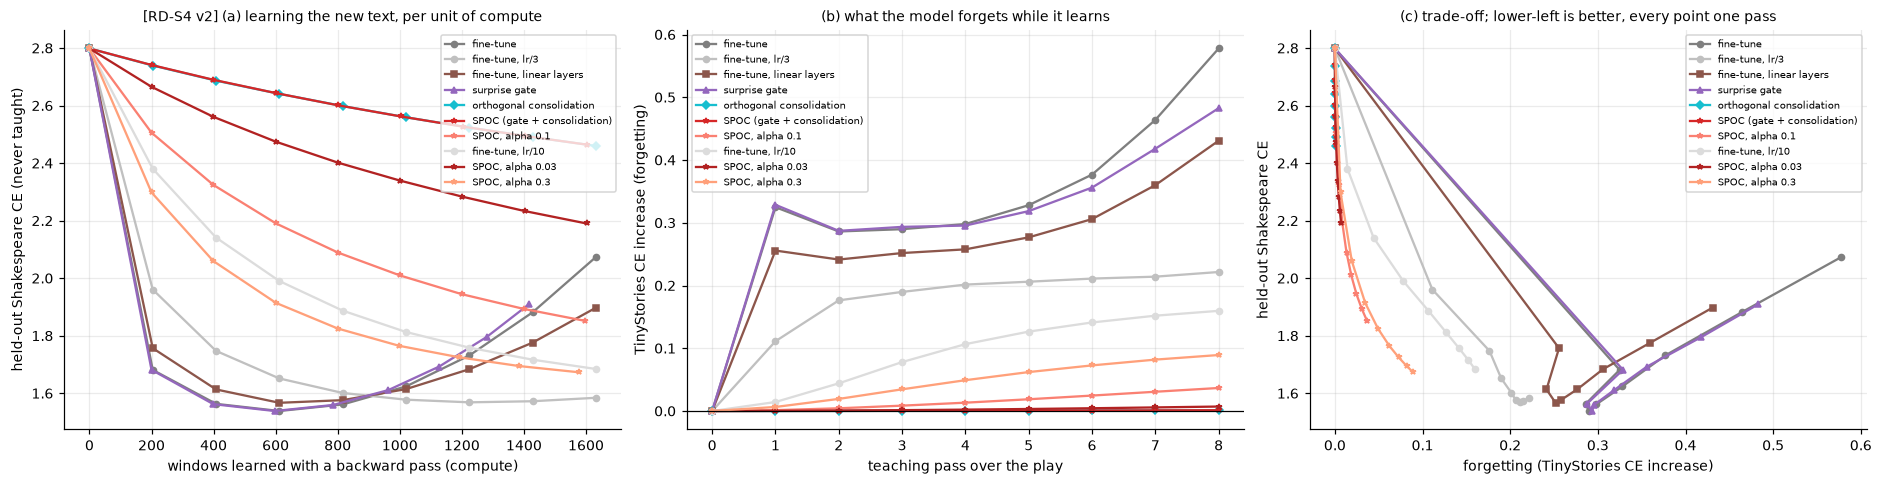

In [9]:
RP.fig_dream(R)
dt = RP.dream_table(R)
print(f"{'method':<30}{'held-out CE':>14}{'learned':>10}{'forgetting':>12}{'backward':>10}{'screened':>10}{'seconds':>9}")
for m, r in dt.items():
    print(f"{m:<30}{r['held_ce'][0]:>8.3f}±{r['held_ce'][1]:.3f}{r['learned'][0]:>+10.3f}{r['forgetting'][0]:>+12.4f}"
          f"{r['backward_windows'][0]:>10.0f}{r['screen_windows'][0]:>10.0f}{r['wall_s'][0]:>9.1f}")
fr = RP.dream_frontier(R)
print("\nbest held-out Shakespeare CE reachable without forgetting more than a given amount of TinyStories "
      "(any setting, any pass; mean of 3 models):")
lims = sorted({float(k) for v in fr.values() for k in v})
print(f"{'family':<44}" + "".join(f"{f'forget <= {l:g}':>18}" for l in lims))
for f, v in fr.items():
    print(f"{f:<44}" + "".join(f"{(format(v[str(l)]['held_ce'], '.3f') if str(l) in v else 'n/a'):>18}" for l in lims))

### 10. 🧪 `[T | S4 | Mamba | RD-S4 | v2]` Scorecard

Mean ± sample standard deviation over 3 seeds for quality; medians for speed. An asterisk marks the best value on each row.

In [10]:
print(RP.scorecard_text(R))

metric                                       Transformer                    S4                 Mamba                 RD-S4              RD-S4 v2
------------------------------------------------------------------------------------------------------------------------------------------------
params                                         1,736,448             1,714,944             1,707,980             1,721,760             1,719,980
training tokens (equal FLOPs)                     34.0 M                46.4 M                40.1 M                46.8 M                33.8 M
selected learning rate                             0.003                 0.006                 0.012                 0.012                 0.006
test CE (nats/char)                       0.7675 ±0.0061        0.7383 ±0.0007       *0.6634 ±0.0022        0.7780 ±0.0017        0.6990 ±0.0033
test perplexity (per char)                  2.154 ±0.013          2.092 ±0.001         *1.941 ±0.004          2.177 ±0.004        

## 11. Verdict

### RD-S4 v2 against the acceptance test

| Criterion | Outcome | Evidence (mean ± s.d. over 3 seeds; speed = median of 3 interleaved rounds on AC power) |
|---|---|---|
| Comparable or better perplexity | **Better than S4, the Transformer and v1; behind Mamba** | Test CE 0.6990 ± 0.0033 vs Mamba 0.6634 ± 0.0022 (+0.036), S4 0.7383 (-0.039), Transformer 0.7675 (-0.068), v1 0.7780 (-0.079). Every one of these comparisons separates completely across seeds. At 32K and 128K: 0.670 and 0.669, against 0.632 and 0.632 for Mamba, 0.746 and 0.745 for S4, 0.752 and 0.756 for v1, and 0.740 and 0.742 for a Transformer served with a 512-character window. |
| Materially lower memory at 32K to 128K | **Yes against the Transformer, S4 and v1; no against Mamba** | Decode state 255 KB, against a 96 MB and 384 MB KV cache (386x and 1,543x larger), 384 KB for S4 and 387 KB for v1; Mamba carries 195 KB. Prefill peak 99 MB, against 1,250 MB for the Transformer at 128K, 391 MB for S4 and 410 MB for v1; Mamba peaks at 29 MB. |
| Materially lower latency at 32K to 128K | **Decode: yes against the Transformer and v1, no against Mamba and S4. Prefill: faster than S4 and v1 and, at 128K, the Transformer; 2.7x slower than Mamba** | Decode 3,228 and 3,220 tok/s at 32K and 128K, against 1,370 and 406 for the Transformer (2.4x and 7.9x), 2,559 and 2,548 for v1, 3,699 and 3,691 for Mamba, 4,411 and 4,406 for S4. Prefill 147,333 and 144,517 tok/s, against 400,957 and 110,233 for the Transformer, 387,878 and 389,894 for Mamba, 62,979 and 60,080 for S4, 59,840 and 56,079 for v1. |

### From v1 to v2, measured

| | RD-S4 v1 | RD-S4 v2 | Change |
|---|---|---|---|
| Test CE (nats/char), 3 seeds | 0.7780 ± 0.0017 | 0.6990 ± 0.0033 | -0.079 |
| Perplexity per character | 2.177 | 2.012 | -8 percent |
| Next-character accuracy | 75.43 % | 77.88 % | +2.4 points |
| Controlled retrieval, gap 32 / 192 | +0.010 / +0.002 | +0.040 / +0.039 | 4x / 21x |
| Prefill at 128K | 56,079 tok/s, 410 MB | 144,517 tok/s, 99 MB | 2.6x faster, 4.2x less memory |
| Decode (CUDA graphs) | 2,548 tok/s | 3,220 tok/s | 1.26x |
| Decode state | 387 KB | 255 KB | -34 percent |
| Training time to v1's final quality | 7.0 min (whole budget) | 2.5 min (48 percent of the budget) | 2.8x sooner |
| Auxiliary heads | drafts, JEPA, VICReg, router, evolution: 24 percent of forward FLOPs | JEPA only, training-time | JEPA effect: +0.0008 nats, p = 0.70 (not significant, two-sided) |

### SPOC on a GPU: what pays and what does not

1. **Learning from prediction errors inside the architecture pays.** v2's memory stores only what it fails to
   predict, at every token, in parallel and without a backward pass. That mechanism is where the gains in the table
   above come from, and it is how predictive coding runs efficiently on a GPU: as a forward computation.
2. **The surprise gate does not pay in pre-training.** With its screening charged to the same FLOP budget, the gated
   run learned from 20.4 M characters instead of 33.8 M and finished at test CE 0.767 against 0.698 (seed 0). In a
   single pass over fresh text almost no window is already known, so the gate has nothing to skip.
3. **Predictive-coding relaxation does not pay as a replacement for backprop.** Every relaxation sweep costs about
   one forward and one backward pass through the network, so any PC variant pays several times backprop's cost per
   weight update. With predictions frozen at the feed-forward pass (FPA), PC reproduces backprop exactly from 7
   sweeps (cosine 1.000) but costs 6.1x the time per update: in 120 seconds it makes 62 updates to backprop's 367
   and reaches a selection CE of 1.34 against 0.90. Plain PC, which recomputes its predictions at every sweep, never
   followed the gradient well on v2: across step sizes 0.05 to 0.2, 7 to 200 sweeps, full or reduced output error,
   TF32 or full fp32 arithmetic, its update's cosine with the exact gradient stayed at or below 0.48, and its best
   setting reached a selection CE of 2.49 in 120 seconds. The same code, on a classic predictive-coding network
   (embedding, six tanh MLP blocks, read-out) and the same text, converges to backprop (cosine 0.9999 with a small
   output error, 1.0000 with FPA), so this is a property of the deep normalised network: the embedding's RMSNorm makes the
   first block amplify about 6x (the others 1.02x to 1.05x), which leaves the relaxation ill-conditioned,
   and a separate smaller step for that layer recovers only part of the alignment (0.39 at 200 sweeps).
4. **Orthogonal consolidation pays when the model is taught new text.** Taught *As You Like It* for 8 passes, with
   any learning rate, fine-tuning cannot learn anything while forgetting at most 0.01 nats of TinyStories, and at
   most 0.05 and 0.10 nats of forgetting it reaches held-out Shakespeare CE 2.141 and 1.990. With consolidation the
   same budgets give 2.190, 1.825 and 1.673 (mean of 3 trained models; every setting and pass considered). Fine-tuning
   only gets lower (1.569) by forgetting 0.21 nats. The surprise gate on its own protects nothing (every pass forgets
   0.29 nats or more) and saves 13 percent of backward passes while adding 20 percent of wall-clock in screening.

### Why v2 still trails Mamba

1. **Selectivity granularity.** Each of v2's 8 heads per layer has one write strength and one step size per token.
   A chunked delta-rule memory cannot give every value channel its own gate (each would need its own triangular
   solve), while Mamba selects per channel, 376 per layer. In the pilots, going from 4 to 8 heads gained 0.015 nats;
   12 and 16 heads lost again (key spaces of 16 and 12 dimensions are too small to store associations); per-mode
   data-dependent steps, reflections, a direct skip path and a larger initialisation were neutral.
2. **Arithmetic per token.** The chunk algebra raises training cost to 12.8 MFLOP per character against 10.8 for
   Mamba, so under the shared budget v2 learned from 33.8 M characters and Mamba from 40.1 M.
3. **Kernels.** A 2,048-character prefill chunk runs about 1,300 small PyTorch kernels; nothing is hand-fused.
   Replaying them from a CUDA graph gains 5 to 21 percent (2K to 128K), and compiler fusion raises v2's prefill to
   247K to 297K tok/s (1.7x to 2.1x eager); Mamba's hand-fused scan with the same fusion reaches 430K to 465K.
   v2's complex-valued decode step is not fused by the compiler (3,229 tok/s against 8,124 for compiled Mamba), a limit
   of the implementation.
4. **Seed spread** is 1.5x Mamba's (± 0.003 against ± 0.002).

### What this does and does not show

* One small scale: 1.7 M parameters, character level, one corpus, every model trained at 512 characters.
* Three seeds: an exact permutation test cannot go below p = 0.05 one-sided, which here means complete separation.
* v2's shape was chosen by pilots on the selection split (never the test split); its learning-rate optimum is
  interior to the sweep (6e-3, between 3e-3 and 1.2e-2).
* v2's training step is compiled, the other arms' are not; this changes training wall-clock only, never the FLOP
  budget.
* All RD-S4 v2 runs and every speed measurement of this edition ran on AC power: the supply was logged every
  30 seconds from 20:58 to 22:34 (195 samples, none on battery), and the runs that
  started earlier trained at the same speed as the later ones (151 to 152 ms per step).
* **Run-to-run variation.** Every RD-S4 v2 number here comes from its second full run, with the model loaded from the
  main notebook (`RD-S4_EFR_TinyStories.ipynb`); the first run, with the same architecture loaded from a Python
  module and checked to give bitwise-identical outputs, is archived in `results/archive_v2_module_2026-10-11/`. Test CE: 0.6939 ± 0.0041
  in the first run, 0.6990 ± 0.0033 in this one. The same code and seed gave selection CEs up to 0.0075 apart
  across the 4 learning rates of the sweep, because GPU kernels are not bitwise deterministic; differences of that
  size between two arms are noise, which is why the comparisons above rest on complete separation across seeds.

### What would have to change next

1. A fused kernel for the chunked memory, as flash-linear-attention provides for delta-rule models: engineering
   rather than architecture, worth about 2x prefill on the compiler evidence above.
2. A real-valued decode step the compiler can fuse.
3. Per-channel selectivity without losing the chunked form, for example a small per-channel selective path beside
   the memory, tested in this same harness.
4. Scale: delta-rule memories improve with key dimension, and at 1.7 M parameters 8 heads of 24 dimensions was the
   best measured trade-off.


## 12. Reproduce

```bash
cd ML/WithPython/benchmarks/four_way
python run.py check     # parity of every fast path (random weights)
python run.py plan      # FLOPs per step -> equal-budget step counts
python run.py sweep     # learning-rate sweep, seed 0, all arms
python run.py seeds     # seeds 0-2 at each arm's selected rate
python run.py eval      # test CE/PPL (all seeds)
python run.py eval2     # full-context vs 512-window CE at 8K/32K/128K; controlled retrieval
python run.py speed     # prefill / decode / memory, 2K-128K (eager and CUDA-graph prefill)
python ablate_v2.py     # RD-S4 v2 without JEPA (3 seeds); RD-S4 v2 with the SPOC surprise gate
python dream_v2.py      # day-dreaming: teach Shakespeare, measure forgetting
python pc_cost.py       # predictive-coding relaxation vs backprop on RD-S4 v2
python pc_steps.py      # plain PC: relaxation step sizes, output-error scale, equal wall-clock race
python pc_checks.py     # PC: value-node scales, TF32 vs fp32, per-layer step, classic-MLP control
python speed_compiled.py  # supplementary: every chunked recurrent arm compiled by TorchInductor
python make_notebook.py # rebuild and execute this notebook from results/
```
Every stage is resumable; finished runs are skipped. Raw per-run histories, per-seed evaluations and every speed
repetition are in `benchmarks/four_way/results/`.
